Loaded ECG samples: 21837
Total exceptions: 0
Epoch 1/25


2026-03-14 00:47:09.675383: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng18{k11=0} for conv %cudnn-conv-bw-filter.4 = (f32[256,12,1,3]{3,2,1,0}, u8[0]{0}) custom-call(f32[64,12,1,200]{3,2,1,0} %bitcast.29874, f32[64,256,1,200]{3,2,1,0} %bitcast.40786), window={size=1x3 pad=0_0x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardFilter", metadata={op_type="Conv2DBackpropFilter" op_name="gradient_tape/Hybrid_Transformer_1/stacked_transformer_ensemble_1/ecg_transformer_1/conv1d_1_1/convolution/Conv2DBackpropFilter" source_file="/usr/local/lib/python3.12/dist-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kNone","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false} is taking a while...
2026-03-14 00:47:11.297849: E external/local_xla/xla/service/slow_operat

128/128 ━━━━━━━━━━━━━━━━━━━━ 93s 462ms/step - accuracy: 0.6539 - loss: 0.6293 - val_accuracy: 0.7417 - val_loss: 0.5322
Epoch 2/25
128/128 ━━━━━━━━━━━━━━━━━━━━ 35s 271ms/step - accuracy: 0.7424 - loss: 0.5186 - val_accuracy: 0.7624 - val_loss: 0.5063
Epoch 3/25
128/128 ━━━━━━━━━━━━━━━━━━━━ 35s 275ms/step - accuracy: 0.7585 - loss: 0.4934 - val_accuracy: 0.7845 - val_loss: 0.4790
Epoch 4/25
128/128 ━━━━━━━━━━━━━━━━━━━━ 34s 262ms/step - accuracy: 0.7655 - loss: 0.4721 - val_accuracy: 0.7790 - val_loss: 0.4611
Epoch 5/25
128/128 ━━━━━━━━━━━━━━━━━━━━ 35s 270ms/step - accuracy: 0.7779 - loss: 0.4602 - val_accuracy: 0.7901 - val_loss: 0.4502
Epoch 6/25
128/128 ━━━━━━━━━━━━━━━━━━━━ 34s 266ms/step - accuracy: 0.7896 - loss: 0.4368 - val_accuracy: 0.7942 - val_loss: 0.4360
Epoch 7/25
128/128 ━━━━━━━━━━━━━━━━━━━━ 34s 267ms/step - accuracy: 0.8017 - loss: 0.4334 - val_accuracy: 0.8039 - val_loss: 0.4352
Epoch 8/25
128/128 ━━━━━━━━━━━━━━━━━━━━ 34s 267ms/step - accuracy: 0.7988 - loss: 0.4240 - val

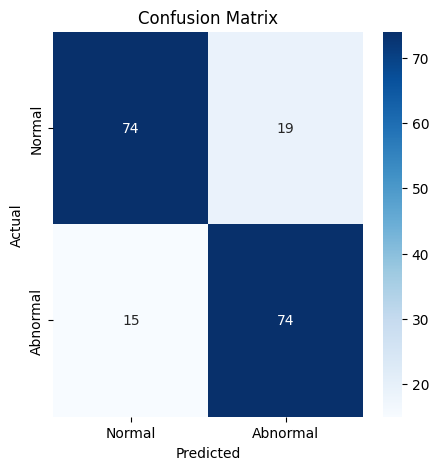

Model: "Hybrid_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ECG_Input           │ (None, 200, 12)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ PCG_Input           │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ecg_transformer     │ (None, 256)       │  2,377,472 │ ECG_Input[0][0]   │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pcg_transformer     │ (None, 256)       │  2,433,280 │ PCG_Input[0][0]   │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 512)       │          0 │ ecg_transformer[… │
│ (Concatenate)       │                   │            │ pcg_transformer[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 256)       │    131,328 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 1, 256)    │          0 │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block   │ (None, 1, 256)    │  2,367,488 │ reshape_3[0][0]   │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 256)       │          0 │ transformer_bloc… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stacked_transforme… │ (None, 256)       │  4,810,752 │ ECG_Input[0][0],  │
│ (Functional)        │                   │            │ PCG_Input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 512)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ stacked_transfor… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 2)         │      1,026 │ concatenate_3[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,931,784 (83.66 MB)

 Trainable params: 7,310,594 (27.89 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 14,621,190 (55.78 MB)

In [7]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, losses
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from imblearn.over_sampling import SMOTE
from scipy.io import wavfile
from scipy.signal import stft
import wfdb
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import glob
import ast

# Constants
IMG_HEIGHT = 128
IMG_WIDTH = 128
PATCH_SIZE = 16
EMBED_DIM = 256
NUM_HEADS = 8
FF_DIM = 512
DROPOUT_RATE = 0.3
NUM_CLASSES = 2
INPUT_ECG_SHAPE = (200, 12)  # 200 samples, 12 leads
INPUT_PCG_SHAPE = (IMG_HEIGHT, IMG_WIDTH, 1)
BATCH_SIZE = 64
EPOCHS = 25
LEARNING_RATE = 1e-5

# Helper function to compute PCG spectrogram
def compute_spectrogram(filepath):
    sample_rate, signal = wavfile.read(filepath)
    frequencies, times, spectrogram = stft(signal, fs=sample_rate, nperseg=256)
    spectrogram = np.log(np.abs(spectrogram) + 1e-10)
    spectrogram = np.resize(spectrogram, (IMG_HEIGHT, IMG_WIDTH))
    return spectrogram

# Load PCG dataset with augmentation for abnormal cases
def load_pcg_dataset(normal_dir, abnormal_dir):
    data, labels = [], []
    for label, directory in enumerate([normal_dir, abnormal_dir]):
        for filename in os.listdir(directory):
            if filename.endswith(".wav"):
                filepath = os.path.join(directory, filename)
                spectrogram = compute_spectrogram(filepath)
                data.append(spectrogram)
                labels.append(label)
                # Augment abnormal data by flipping
                if label == 1:
                    flipped_spectrogram = np.flip(spectrogram, axis=1)
                    data.append(flipped_spectrogram)
                    labels.append(label)
    return np.array(data), np.array(labels)

# --- PTB-XL ECG Data Loader (all leads, records100/records500 aware) ---
def load_ptbxl_ecg_data(csv_path, records_base_path, num_samples=200, records_subfolder="records100"):
    df = pd.read_csv(csv_path)
    records_path = os.path.join(records_base_path, records_subfolder)
    available_records = []
    for root, dirs, files in os.walk(records_path):
        for file in files:
            if file.endswith('.hea'):
                available_records.append(os.path.relpath(os.path.join(root, file), records_path).replace('.hea', ''))
    available_records = set(available_records)
    df = df[df['ecg_id'].astype(str).str.zfill(5).apply(lambda rid: any(rid in rec for rec in available_records))]
    X, Y = [], []
    exception_count = 0
    for idx, row in df.iterrows():
        rec_id = str(row['ecg_id']).zfill(5)
        # Find all matching records (e.g., 00001_lr, 00001_hr, etc.)
        rec_candidates = [rec for rec in available_records if os.path.basename(rec).startswith(rec_id)]
        if not rec_candidates:
            if exception_count < 5:
                print(f"No matching record file for ecg_id {rec_id}")
            exception_count += 1
            continue
        rec_file = rec_candidates[0]
        rec_path = os.path.join(records_path, rec_file)
        try:
            signal, fields = wfdb.rdsamp(rec_path)
            # Use all 12 leads, shape: (time, 12)
            if signal.shape[0] < num_samples or signal.shape[1] < 12:
                continue
            # Take a random segment of num_samples
            start = np.random.randint(0, signal.shape[0] - num_samples + 1)
            segment = signal[start:start+num_samples, :12]  # shape (num_samples, 12)
            X.append(segment)
            scp_codes = ast.literal_eval(row['scp_codes']) if isinstance(row['scp_codes'], str) else row['scp_codes']
            label = 0 if 'NORM' in scp_codes else 1
            Y.append(label)
        except Exception as e:
            if exception_count < 5:
                print(f"Exception for record {rec_id}: {e}")
            exception_count += 1
            continue
    print(f"Loaded ECG samples: {len(X)}")
    print(f"Total exceptions: {exception_count}")
    return np.array(X), np.array(Y)

# Map ECG labels to binary classes
def label_ecg(y):
    normal_classes = ['N', 'L', 'R']
    return 0 if y in normal_classes else 1

# Data paths
pcg_normal_dir = "/kaggle/input/datasets/mahirazmainhaque/combined-heart-sound-dataphysionet-circor1/combined_heart_sound_data(physionet +circor)/Normal"
pcg_abnormal_dir = "/kaggle/input/datasets/mahirazmainhaque/combined-heart-sound-dataphysionet-circor1/combined_heart_sound_data(physionet +circor)/Abnormal"
# Set the correct PTB-XL base path and use records100 by default
ptbxl_base_path = "/kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1"
ptbxl_csv = os.path.join(ptbxl_base_path, "ptbxl_database.csv")
ptbxl_records_subfolder = "records100"  # Change to "records500" if you want to use that

# Load and preprocess PCG data
pcg_data, pcg_labels = load_pcg_dataset(pcg_normal_dir, pcg_abnormal_dir)
pcg_data = pcg_data / np.max(pcg_data)
pcg_data = np.expand_dims(pcg_data, -1)
pcg_labels = tf.keras.utils.to_categorical(pcg_labels, NUM_CLASSES)

# Load and preprocess ECG data from PTB-XL (all leads, random segment)
X_clean, Y_clean = load_ptbxl_ecg_data(ptbxl_csv, ptbxl_base_path, num_samples=200, records_subfolder=ptbxl_records_subfolder)
scaler = StandardScaler()
X_clean = np.array([scaler.fit_transform(x) for x in X_clean])
Y_clean = np.array(Y_clean)

# Apply SMOTE to balance ECG dataset if not empty
if X_clean.shape[0] > 0:
    smote = SMOTE(random_state=42)
    X_clean_reshaped = X_clean.reshape((X_clean.shape[0], -1))
    X_clean_bal, Y_clean_bal = smote.fit_resample(X_clean_reshaped, Y_clean)
    X_clean_bal = X_clean_bal.reshape((-1, 200, 12))
    Y_clean_bal = tf.keras.utils.to_categorical(Y_clean_bal, NUM_CLASSES)
else:
    X_clean_bal = np.empty((0, 200, 12))
    Y_clean_bal = np.empty((0, NUM_CLASSES))

# Balance datasets
min_samples = min(len(X_clean_bal), len(pcg_data))
X_clean_bal, Y_clean_bal = shuffle(X_clean_bal[:min_samples], Y_clean_bal[:min_samples], random_state=42)
pcg_data, pcg_labels = shuffle(pcg_data[:min_samples], pcg_labels[:min_samples], random_state=42)

# Train-test split
x_train_pcg, x_test_pcg, y_train_pcg, y_test_pcg = train_test_split(pcg_data, pcg_labels, test_size=0.1, random_state=42)
x_val_pcg, x_test_pcg, y_val_pcg, y_test_pcg = train_test_split(x_test_pcg, y_test_pcg, test_size=0.2, random_state=42)

x_train_ecg, x_test_ecg, y_train_ecg, y_test_ecg = train_test_split(X_clean_bal, Y_clean_bal, test_size=0.1, random_state=42)
x_val_ecg, x_test_ecg, y_val_ecg, y_test_ecg = train_test_split(x_test_ecg, y_test_ecg, test_size=0.2, random_state=42)

# Patch Embedding Layer for PCG
def patch_embedding(input_shape, patch_size, embed_dim):
    inputs = layers.Input(shape=input_shape)
    patches = layers.Conv2D(embed_dim, (patch_size, patch_size), strides=(patch_size, patch_size))(inputs)
    flat_patches = layers.Reshape((-1, embed_dim))(patches)
    return models.Model(inputs, flat_patches, name="patch_embedding")

# Transformer Block
def transformer_block(embed_dim, num_heads, ff_dim, dropout_rate):
    inputs = layers.Input(shape=(None, embed_dim))
    attention_output = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)(inputs, inputs)
    attention_output = layers.Dropout(dropout_rate)(attention_output)
    attention_output = layers.LayerNormalization(epsilon=1e-6)(inputs + attention_output)

    ffn_output = layers.Dense(ff_dim, activation='relu')(attention_output)
    ffn_output = layers.Dense(embed_dim)(ffn_output)
    ffn_output = layers.Dropout(dropout_rate)(ffn_output)
    outputs = layers.LayerNormalization(epsilon=1e-6)(attention_output + ffn_output)

    return models.Model(inputs, outputs, name="transformer_block")

# ECG Transformer Model
def ecg_transformer(input_shape, embed_dim, num_heads, ff_dim, dropout_rate):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv1D(embed_dim, kernel_size=3, strides=1, padding='same')(inputs)
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x = transformer_block(embed_dim, num_heads, ff_dim, dropout_rate)(x)
    x = layers.GlobalAveragePooling1D()(x)
    return models.Model(inputs, x, name="ecg_transformer")

# PCG Transformer Model
def pcg_transformer(input_shape, patch_size, embed_dim, num_heads, ff_dim, dropout_rate):
    inputs = layers.Input(shape=input_shape)
    x = patch_embedding(input_shape, patch_size, embed_dim)(inputs)
    x = transformer_block(embed_dim, num_heads, ff_dim, dropout_rate)(x)
    x = layers.GlobalAveragePooling1D()(x)
    return models.Model(inputs, x, name="pcg_transformer")

# Multimodal Fusion Transformer
def fusion_transformer(ecg_output, pcg_output, embed_dim, num_heads, ff_dim, dropout_rate):
    combined = layers.Concatenate()([ecg_output, pcg_output])
    combined = layers.Dense(embed_dim)(combined)
    combined = layers.Reshape((1, embed_dim))(combined)

    combined = transformer_block(embed_dim, num_heads, ff_dim, dropout_rate)(combined)
    combined = layers.GlobalAveragePooling1D()(combined)
    return combined

# Stacked Transformer Ensemble with Weighted Voting
def stacked_transformer_ensemble(models_list, weights):
    inputs = [layers.Input(shape=model.input_shape[1:]) for model in models_list]
    outputs = [model(input) for model, input in zip(models_list, inputs)]
    weighted_outputs = [layers.Lambda(lambda x: x * weight)(output) for output, weight in zip(outputs, weights)]
    stacked_output = layers.Average()(weighted_outputs)
    return models.Model(inputs, stacked_output, name="stacked_transformer_ensemble")

# Final Hybrid Model
def hybrid_transformer_model():
    ecg_input = layers.Input(shape=INPUT_ECG_SHAPE, name="ECG_Input")
    pcg_input = layers.Input(shape=INPUT_PCG_SHAPE, name="PCG_Input")

    ecg_model = ecg_transformer(INPUT_ECG_SHAPE, EMBED_DIM, NUM_HEADS, FF_DIM, DROPOUT_RATE)
    pcg_model = pcg_transformer(INPUT_PCG_SHAPE, PATCH_SIZE, EMBED_DIM, NUM_HEADS, FF_DIM, DROPOUT_RATE)

    ecg_output = ecg_model(ecg_input)
    pcg_output = pcg_model(pcg_input)

    fusion_output = fusion_transformer(ecg_output, pcg_output, EMBED_DIM, NUM_HEADS, FF_DIM, DROPOUT_RATE)

    # Stacked Transformer Ensemble
    models_list = [ecg_model, pcg_model]
    weights = [0.5, 0.5]  # Adjust weights based on model performance
    stacked_output = stacked_transformer_ensemble(models_list, weights)([ecg_input, pcg_input])

    # Combine Fusion and Stacked Outputs
    combined_output = layers.Concatenate()([fusion_output, stacked_output])
    outputs = layers.Dense(NUM_CLASSES, activation='sigmoid')(combined_output)

    model = models.Model(inputs=[ecg_input, pcg_input], outputs=outputs, name="Hybrid_Transformer")
    model.compile(optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss=losses.BinaryCrossentropy(),
                  metrics=['accuracy'])

    return model

model = hybrid_transformer_model()
history = model.fit(
    [x_train_ecg, x_train_pcg], y_train_ecg,
    validation_data=([x_val_ecg, x_val_pcg], y_val_ecg),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)
y_pred_prob = model.predict([x_test_ecg, x_test_pcg])
y_pred = (y_pred_prob[:, 1] > 0.4).astype(int)  # Adjusted threshold for better recall
y_true = np.argmax(y_test_ecg, axis=1)

print("Classification Report:")
print(classification_report(y_true, y_pred))
print("AUC-ROC:", roc_auc_score(y_true, y_pred_prob[:, 1]))

plt.figure(figsize=(5, 5))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Abnormal'], yticklabels=['Normal', 'Abnormal'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

model.summary()



In [2]:
! pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.2 MB/s eta 0:00:0000:01


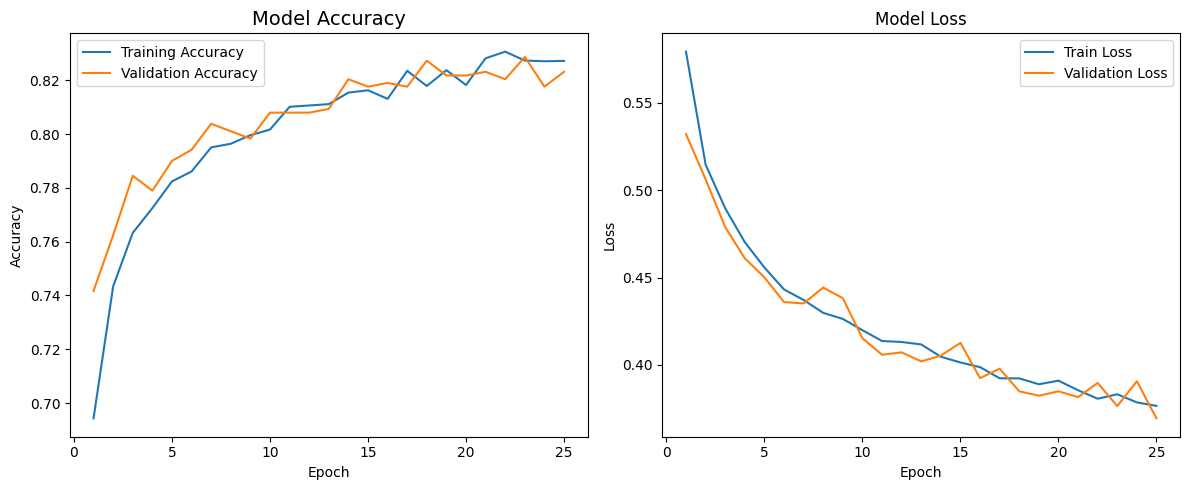

In [8]:
import matplotlib.pyplot as plt

# Extract data from history
train_accuracy = history.history.get('accuracy', [])
val_accuracy = history.history.get('val_accuracy', [])
train_loss = history.history.get('loss', [])
val_loss = history.history.get('val_loss', [])

epochs = range(1, len(train_accuracy) + 1)

# Plotting model accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracy, label='Training Accuracy')
plt.plot(epochs, val_accuracy, label='Validation Accuracy')
plt.title('Model Accuracy', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plotting model loss
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, label='Train Loss')  # Updated training color
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
# Set DPI to 300
plt.tight_layout()
plt.savefig('Hybrid_model.png', dpi=300)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.84      0.82        93
           1       0.82      0.78      0.80        89

    accuracy                           0.81       182
   macro avg       0.81      0.81      0.81       182
weighted avg       0.81      0.81      0.81       182



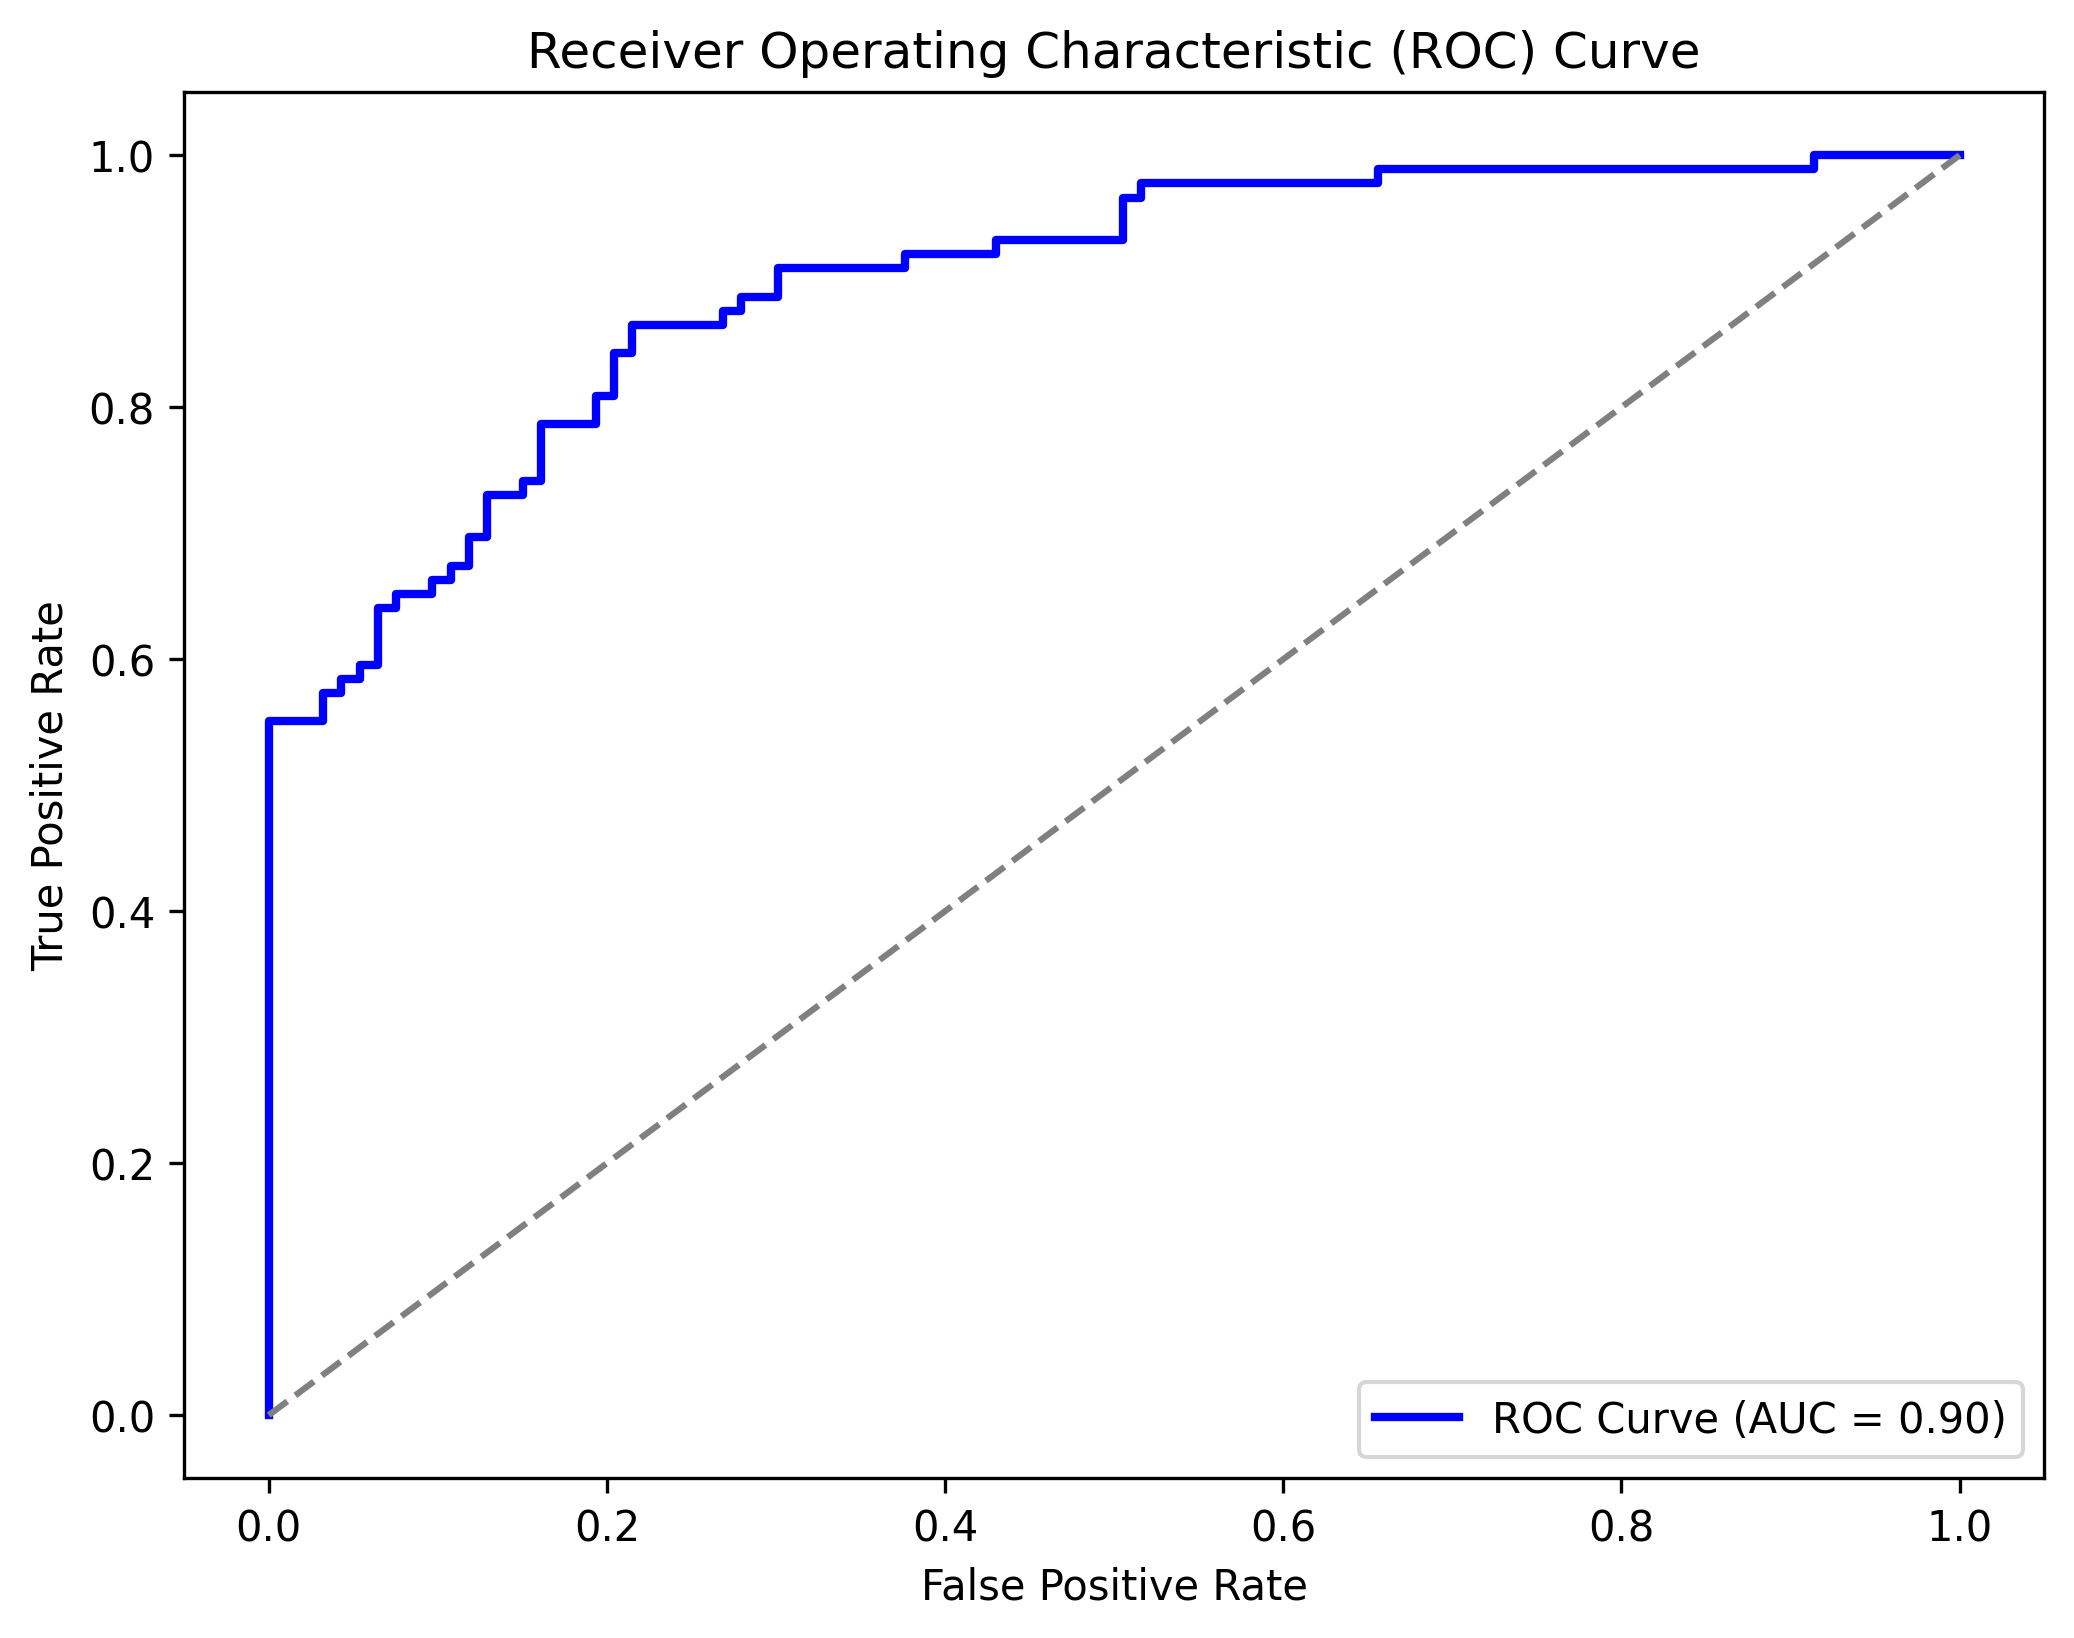

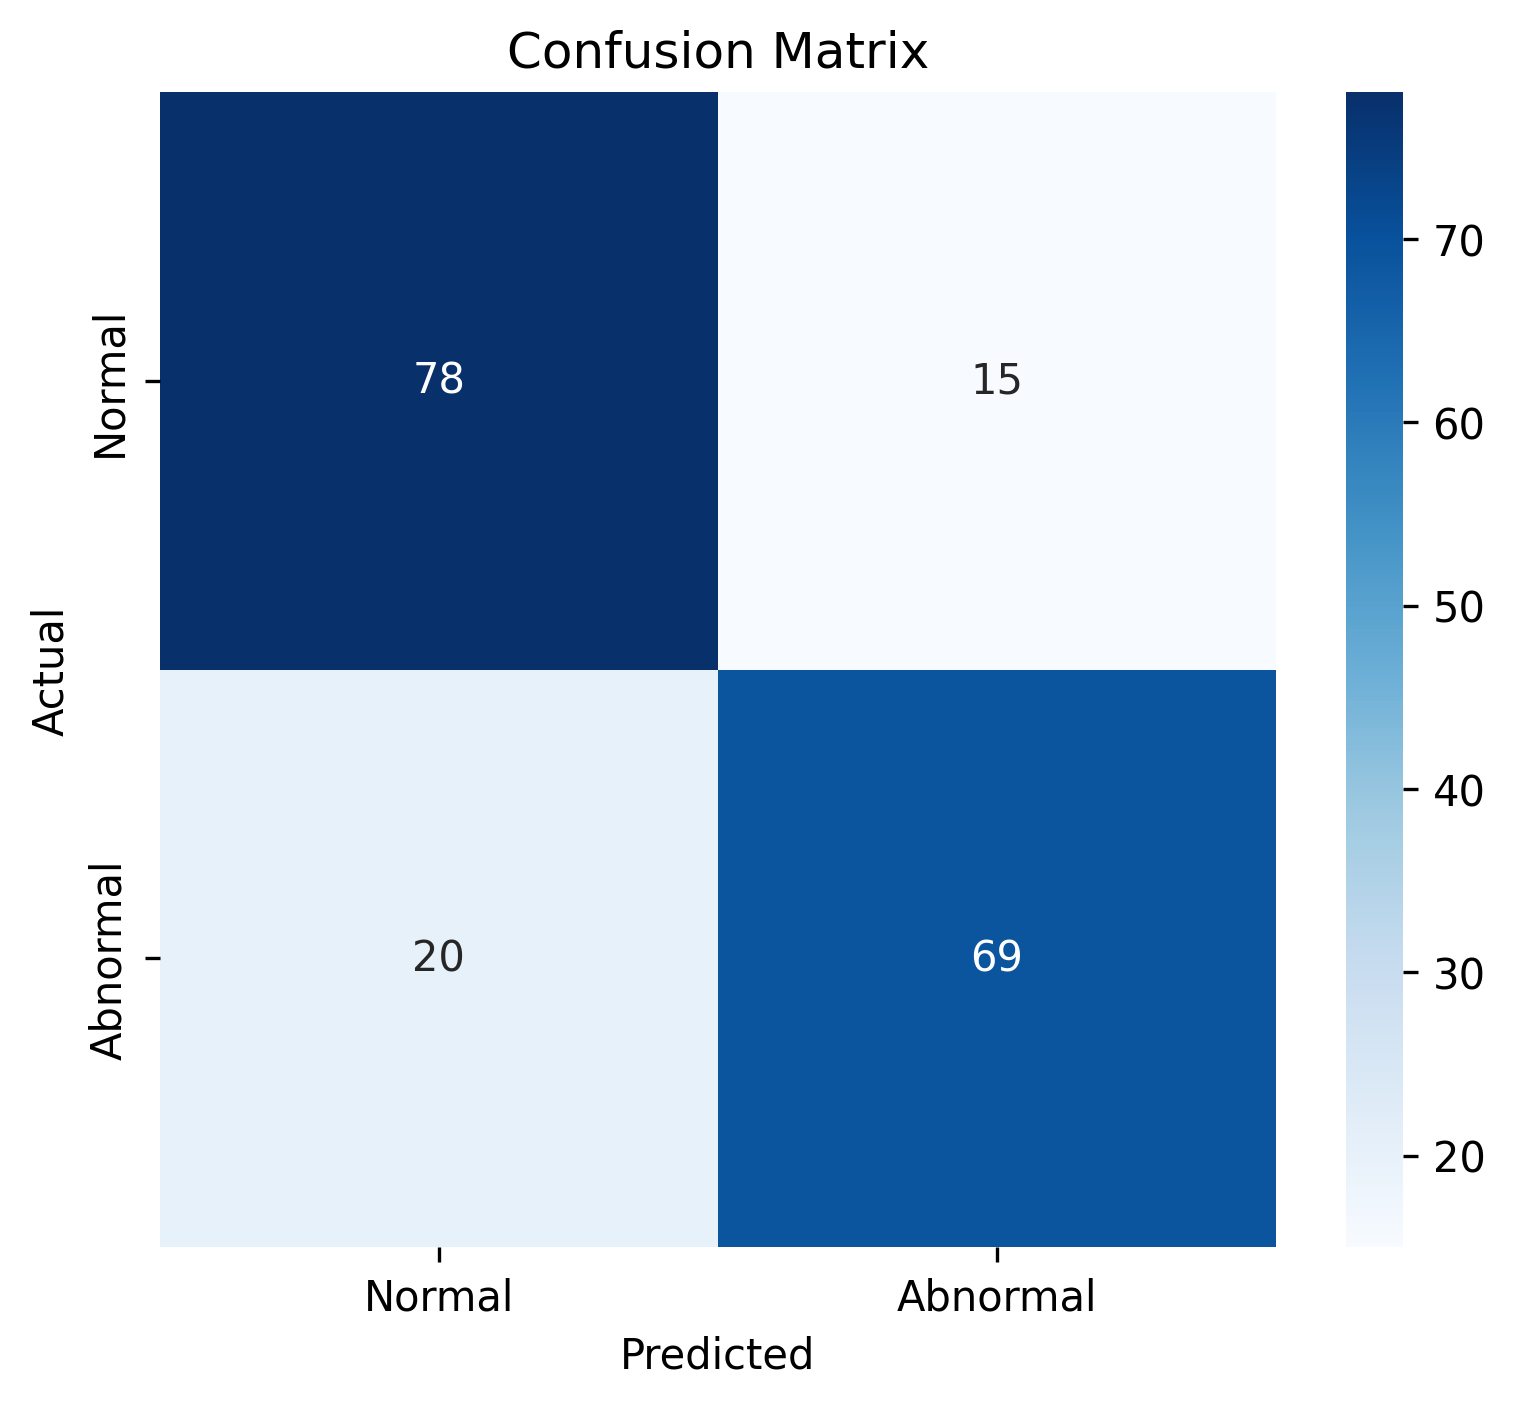

In [9]:
from sklearn.metrics import roc_curve, auc, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions
y_pred_probs = model.predict([x_test_ecg, x_test_pcg])  # Probabilities
y_pred_classes = np.argmax(y_pred_probs, axis=1)  # Convert to class labels
y_true = np.argmax(y_test_ecg, axis=1)  # True labels (assuming same for ECG & PCG)

# Compute ROC AUC Score
fpr, tpr, _ = roc_curve(y_true, y_pred_probs[:, 1])
roc_auc = auc(fpr, tpr)

# Generate Classification Report
class_report = classification_report(y_true, y_pred_classes)
print("Classification Report:\n", class_report)

# Generate Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes)

# Plot ROC Curve
plt.figure(figsize=(8, 6), dpi=300)
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.savefig("roc_curve.png", dpi=300)  # Save at 300 dpi
plt.show()

# Plot Confusion Matrix
plt.figure(figsize=(6, 5), dpi=300)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Abnormal"], yticklabels=["Normal", "Abnormal"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300)  # Save at 300 dpi
plt.show()


In [11]:
# Save the trained model to a file
model.save('/kaggle/working/Updated_hybrid_transformer_model.keras')
print("Model saved as 'hybrid_transformer_model.keras'")


Model saved as 'hybrid_transformer_model.keras'
